# FIAP — Atividade 2: Análise de conglomerados por geolocalização

## Objetivo
Agrupar as localizações aproximadas das entregas usando latitude e longitude, estimar uma quantidade de grupos e somar o valor das entregas de cada grupo.

In [ ]:
# Importar as bibliotecas utilizadas na análise
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Caminho do CSV. Deixe o arquivo CSV na mesma pasta deste notebook.
arquivo = "Fiap On - Fase 6 - Geolocalização Dataset - Asset.csv"

# Ler tudo inicialmente como texto para controlar a conversão da vírgula decimal.
df_original = pd.read_csv(arquivo, dtype=str)

# Criar uma cópia para tratamento, preservando a base original.
df = df_original.copy()

# Converter as colunas numéricas: por exemplo, "52,47" passa a ser 52.47.
colunas_numericas = ["latitude", "longitude", "price"]
for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(
        df[coluna].str.replace(",", ".", regex=False),
        errors="coerce"
    )

print("Quantidade de linhas e colunas:", df.shape)
display(df.head())
print("\nTipos de dados após o tratamento:")
print(df.dtypes)

Quantidade de linhas e colunas: (653, 3)


,latitude,longitude,price
0,-21.59136,-51.06669,52.47
1,-21.28535,-49.65497,37.03
2,-22.02590,-47.06702,71.50
3,-21.91623,-46.68666,88.27
4,-22.47639,-46.63278,36.16



Tipos de dados após o tratamento:
latitude     float64
longitude    float64
price        float64
dtype: object


## 1. Verificar a qualidade dos dados

Vamos conferir valores ausentes, duplicidades e estatísticas básicas. A base original continua intacta; qualquer tratamento é aplicado apenas ao DataFrame usado na análise.

In [ ]:
# Conferir valores ausentes em cada coluna
print("Valores ausentes por coluna:")
display(df.isna().sum())

# Conferir linhas duplicadas
print("Quantidade de linhas duplicadas:", df.duplicated().sum())

# Estatísticas descritivas das colunas numéricas
display(df.describe())

# O K-Means não pode ser executado com coordenadas ausentes.
# Como a base deste exercício não apresenta valores ausentes após a conversão,
# nenhuma linha precisa ser removida neste caso.
df_analise = df.dropna(subset=["latitude", "longitude", "price"]).copy()
print("Registros usados na análise:", len(df_analise))

Valores ausentes por coluna:


latitude     0
longitude    0
price        0
dtype: int64

Quantidade de linhas duplicadas: 0


,latitude,longitude,price
count,653.000000,653.000000,653.000000
mean,-22.151112,-48.636021,63.068622
std,1.176863,1.736983,28.200606
min,-25.014720,-52.819420,12.120000
25%,-23.056670,-50.040700,39.160000
50%,-22.210560,-48.615830,65.020000
75%,-21.184130,-47.290090,85.890000
max,-19.922120,-44.334130,111.710000


Registros usados na análise: 653


## 2. Visualizar a distribuição das localizações

Cada ponto representa uma localização presente na amostra. Como as coordenadas são aproximadas, o gráfico serve para observar a distribuição relativa dos pontos.

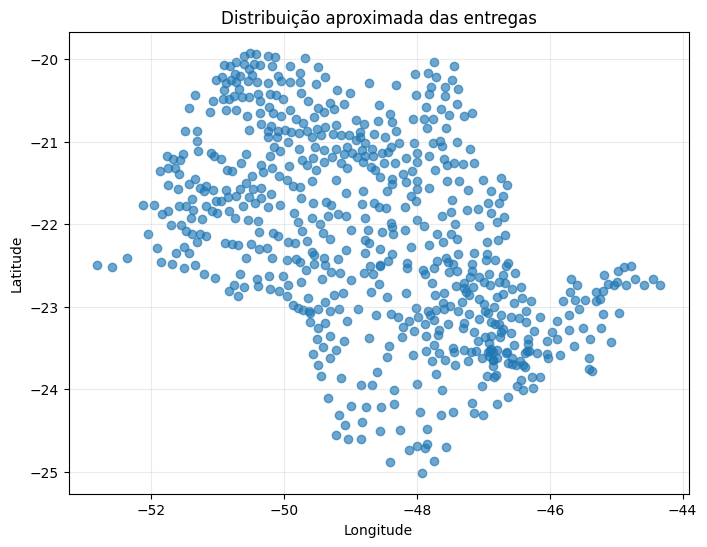

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(df_analise["longitude"], df_analise["latitude"], alpha=0.65)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribuição aproximada das entregas")
plt.grid(True, alpha=0.25)
plt.show()

## 3. Escolher a quantidade de grupos com o método do cotovelo

O K-Means precisa receber previamente o número de grupos (`k`). O método do cotovelo testa diferentes valores de `k` e compara a soma das distâncias quadráticas dos pontos aos centroides (`inertia_`). Procuramos um ponto em que adicionar grupos passe a reduzir essa medida menos intensamente.

O gráfico é um apoio à decisão, não uma regra automática nem uma garantia do número ideal de centros físicos.

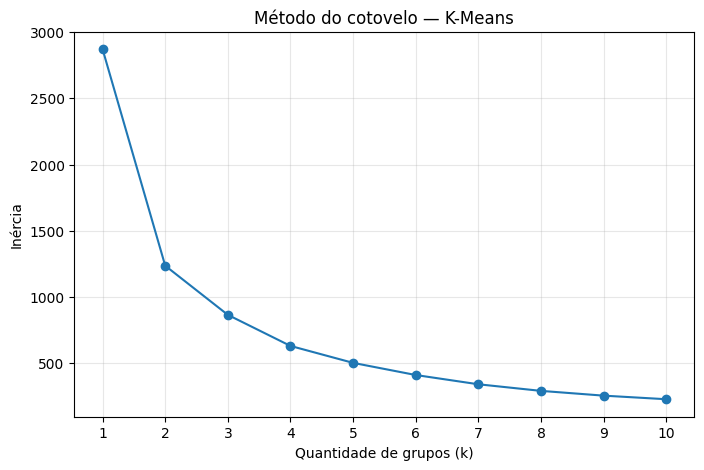

In [ ]:
# Usar somente latitude e longitude para formar os grupos.
# O valor da entrega será somado depois, conforme solicitado no enunciado.
X = df_analise[["latitude", "longitude"]]

valores_k = range(1, 11)
inertias = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X)
    inertias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), inertias, marker="o")
plt.xlabel("Quantidade de grupos (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — K-Means")
plt.xticks(list(valores_k))
plt.grid(True, alpha=0.3)
plt.show()

## 4. Executar o K-Means

Após observar o gráfico do cotovelo, escolha um valor de `k`. Neste notebook, `k = 4` é usado como uma **escolha inicial para análise**; confira se esse valor faz sentido ao observar o gráfico e os resultados. Se a curva sugerir outra escolha, altere `K_ESCOLHIDO` e execute novamente as células seguintes.

In [ ]:
# Ajuste este valor após interpretar o gráfico do cotovelo.
K_ESCOLHIDO = 4

modelo = KMeans(n_clusters=K_ESCOLHIDO, random_state=42, n_init=10)
df_analise["grupo"] = modelo.fit_predict(X)

# Mostrar quantos registros foram atribuídos a cada grupo
print("Quantidade de registros por grupo:")
display(df_analise["grupo"].value_counts().sort_index())

Quantidade de registros por grupo:


grupo
0    175
1    207
2    126
3    145
Name: count, dtype: int64

## 5. Somar o valor das entregas por grupo

A coluna `price` não participa do agrupamento geográfico. Ela é usada nesta etapa para calcular o valor total associado a cada grupo.

In [ ]:
resumo_grupos = (
    df_analise.groupby("grupo")
    .agg(
        quantidade_entregas=("price", "size"),
        valor_total_entregas=("price", "sum"),
        latitude_media=("latitude", "mean"),
        longitude_media=("longitude", "mean")
    )
    .reset_index()
)

# Arredondar apenas a apresentação dos resultados
resumo_grupos["valor_total_entregas"] = resumo_grupos["valor_total_entregas"].round(2)
resumo_grupos["latitude_media"] = resumo_grupos["latitude_media"].round(6)
resumo_grupos["longitude_media"] = resumo_grupos["longitude_media"].round(6)

display(resumo_grupos)
print("Valor total da coluna price na base:", round(df_analise["price"].sum(), 2))

,grupo,quantidade_entregas,valor_total_entregas,latitude_media,longitude_media
0,0,175,11067.97,-23.105233,-46.510375
1,1,207,12838.25,-21.331582,-50.637534
2,2,126,7837.20,-23.298522,-48.683372
3,3,145,9440.39,-21.172480,-48.302978


Valor total da coluna price na base: 41183.81


## 6. Visualizar os grupos e seus centroides

As cores representam os grupos encontrados. Os marcadores em formato de X indicam os centroides matemáticos calculados pelo K-Means. Eles são referências analíticas, não endereços recomendados automaticamente para construir os centros.

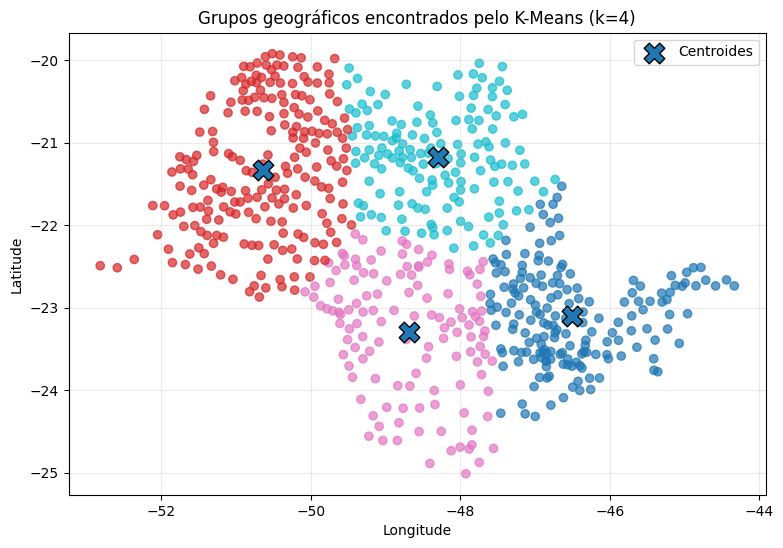

In [ ]:
plt.figure(figsize=(9, 6))
pontos = plt.scatter(
    df_analise["longitude"],
    df_analise["latitude"],
    c=df_analise["grupo"],
    cmap="tab10",
    alpha=0.7
)

centroides = modelo.cluster_centers_
plt.scatter(
    centroides[:, 1],
    centroides[:, 0],
    marker="X",
    s=220,
    edgecolors="black",
    label="Centroides"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Grupos geográficos encontrados pelo K-Means (k={K_ESCOLHIDO})")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

## Conclusão final

**Algoritmo escolhido e justificativa**

Foi utilizado o **K-Means**, com apenas latitude e longitude como variáveis de entrada. A escolha se justifica porque o objetivo é dividir as entregas em grupos geográficos, cada um com um centroide que sirva de referência para a localização de um centro de distribuição. O K-Means faz exatamente isso, é simples de interpretar e funciona bem com 653 registros e duas variáveis numéricas na mesma escala (graus). A variável `price` ficou fora do agrupamento e foi usada apenas depois, para somar o valor das entregas de cada grupo. Para definir o número de grupos, usei o método do cotovelo e adotei **k = 4**: a inércia cai de forma acentuada até k = 3 ou 4 e passa a diminuir mais lentamente a partir daí.

**Resultados**

| Grupo | Entregas | Valor total (R$) |
|---|---|---|
| 0 | 175 | 11.067,97 |
| 1 | 207 | 12.838,25 |
| 2 | 126 | 7.837,20 |
| 3 | 145 | 9.440,39 |

A soma dos quatro grupos (41.183,81) coincide com o valor total da base, o que confirma que nenhuma entrega foi perdida ou contada em duplicidade. Os grupos ficaram razoavelmente equilibrados em tamanho e em valor. O grupo 1 (oeste, longitude média ≈ -50,6) concentra o maior volume e o maior valor, e o grupo 2 (sul, latitude média ≈ -23,3) concentra o menor.

**Avaliação da análise**

Considero a análise **bem-sucedida para o objetivo proposto**: os dados não tinham valores ausentes nem duplicados, os grupos formaram regiões geográficas coerentes e sem sobreposição visível, e o valor total por grupo foi calculado corretamente. Há, porém, algumas limitações:

- O cotovelo é suave e não há um ponto de quebra nítido, então k = 4 é uma escolha razoável, mas não a única possível (k = 3 ou 5 também seriam defensáveis).
- As entregas estão distribuídas de forma contínua pelo território, sem aglomerados naturais bem separados. Por isso o K-Means está **particionando a região** em áreas, e não descobrindo grupos que já existiam nos dados.
- Os centroides são pontos matemáticos médios. Antes de definir os locais reais dos centros, seria preciso considerar rodovias, custo de terreno e distâncias reais de deslocamento.
- Não foi aplicada nenhuma métrica complementar de validação, como o coeficiente de silhueta. Isso poderia reforçar a escolha de k.

Em resumo, o resultado é útil como apoio à decisão sobre onde posicionar os centros, desde que seja complementado por critérios logísticos e operacionais.